# What is the most optimal skill to learn for Data Analysts?
**Methodology**
1. Continue from last notebook to find the percent of postings with skill
2. Visualize the percentage of skill count and median salary
3. (Optional) Show the technologies which are equivalent to skills and determine base on these

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import seaborn as sns
import ast

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [ ]:
#Filter out data for Data analyst in the US
df_DA = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]
#Cleanup the data with None value and explode job_skills column
df_DA = df_DA.dropna(subset= ['salary_year_avg'])
df_DA = df_DA.explode('job_skills')

In [ ]:
#Group job skill and aggreagate them by count and median function
df_DA_skill = df_DA.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])
df_DA_skill.sort_values(by = 'count', ascending = False, inplace = True)
df_DA_skill = df_DA_skill.rename(columns = {'count': 'skill_count', 'median':'median_salary'})
DA_skill_count = len(df_DA)

#Convert the number of skills into percent formatter
df_DA_skill['skill_percent'] = (df_DA_skill['skill_count']/DA_skill_count)*100
skill_percent = 1.25 
df_DA_skill = df_DA_skill[df_DA_skill['skill_percent'] > skill_percent]
df_DA_skill

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2508,91000.00,14.380734
excel,1808,84392.00,10.366972
python,1431,97500.00,8.205275
tableau,1364,92875.00,7.821101
sas,926,90000.00,5.309633
r,893,92500.00,5.120413
power bi,838,90000.00,4.805046
powerpoint,462,85000.00,2.649083
word,461,81194.75,2.643349


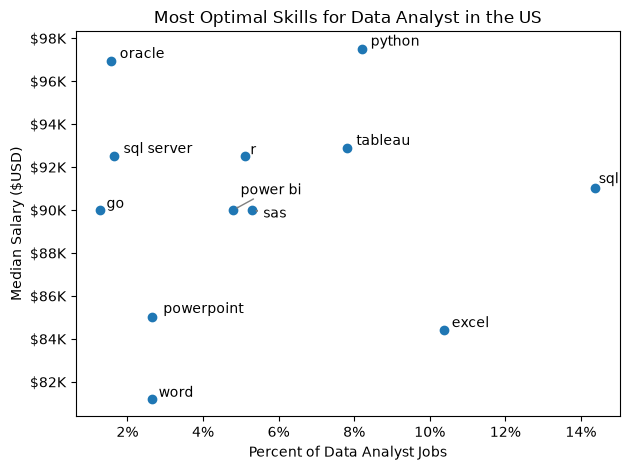

In [ ]:
from adjustText import adjust_text

plt.scatter(df_DA_skill['skill_percent'], df_DA_skill['median_salary'])
sns.set_theme(style='ticks')
#Set labels and title
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Salary ($USD)')
plt.title('Most Optimal Skills for Data Analyst in the US')

#Prepare texts for adjusttext
texts  = []
for i, txt in enumerate(df_DA_skill.index):
    texts.append(plt.text(df_DA_skill['skill_percent'].iloc[i], df_DA_skill['median_salary'].iloc[i], ' ' + txt))

#Adjust text to avoid overlap
adjust_text(texts, arrowprops=dict(arrowstyle= '->', color = 'gray'))

#Set up formatter for xaxis and yaxis
from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals = 0))

#Adjust layout and display plot
plt.tight_layout()
plt.show()

## Bonus: Coloring by Technology  

We are going to add color based on Technology


In [88]:

df_tech = df['job_type_skills'].copy()

# remove duplicates
df_tech = df_tech.drop_duplicates()

# remove NaN values
df_tech = df_tech.dropna()

# combine all dictionaries into one
tech_dict = {}
for row in df_tech:
    row_dict = ast.literal_eval(row)  # convert string to dictionary
    for key, value in row_dict.items():
        if key in tech_dict:  # if key already exists in tech_dict, add value to existing value
            tech_dict[key] += value
        else:                       # if key does not exist in tech_dict, add key and value
            tech_dict[key] = value

# remove duplicates by converting values to set then back to list
for key, value in tech_dict.items():
    tech_dict[key] = list(set(value))

tech_dict

{'analyst_tools': ['dax',
  'msaccess',
  'esquisse',
  'microstrategy',
  'sas',
  'powerpoint',
  'power bi',
  'visio',
  'ssrs',
  'sap',
  'spreadsheet',
  'word',
  'alteryx',
  'powerbi',
  'qlik',
  'tableau',
  'ssis',
  'cognos',
  'sharepoint',
  'datarobot',
  'ms access',
  'spss',
  'looker',
  'nuix',
  'excel',
  'splunk',
  'outlook',
  'sheets'],
 'programming': ['sql',
  'visual basic',
  'scala',
  'lisp',
  'python',
  'shell',
  't-sql',
  'r',
  'javascript',
  'swift',
  'c',
  'php',
  'sas',
  'no-sql',
  'delphi',
  'dart',
  'crystal',
  'cobol',
  'f#',
  'vb.net',
  'mongodb',
  'sass',
  'kotlin',
  'groovy',
  'perl',
  'haskell',
  'bash',
  'apl',
  'typescript',
  'c#',
  'matlab',
  'visualbasic',
  'c++',
  'fortran',
  'css',
  'golang',
  'objective-c',
  'ruby',
  'pascal',
  'solidity',
  'nosql',
  'html',
  'lua',
  'rust',
  'ocaml',
  'julia',
  'java',
  'clojure',
  'erlang',
  'assembly',
  'vba',
  'elixir',
  'mongo',
  'powershell',
  

In [89]:
#Turn dictionary into dataframe
df_technology = pd.DataFrame(list(tech_dict.items()), columns = ['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,dax
0,analyst_tools,msaccess
0,analyst_tools,esquisse
0,analyst_tools,microstrategy
0,analyst_tools,sas
...,...,...
9,sync,unify
9,sync,ringcentral
9,sync,mattermost
9,sync,google chat


In [ ]:
#Merge df_DA_skill with df_technology to visualize median salary and count of skills
df_DA_skills_tech = df_DA_skill.merge(df_technology, left_on = 'job_skills',right_on = 'skills')
df_DA_skills_tech.set_index('skills', inplace = True)
df_DA_skills_tech

,skill_count,median_salary,skill_percent,technology
skills,,,,
sql,2508,91000.00,14.380734,programming
excel,1808,84392.00,10.366972,analyst_tools
python,1431,97500.00,8.205275,programming
tableau,1364,92875.00,7.821101,analyst_tools
sas,926,90000.00,5.309633,analyst_tools
sas,926,90000.00,5.309633,programming
r,893,92500.00,5.120413,programming
power bi,838,90000.00,4.805046,analyst_tools
powerpoint,462,85000.00,2.649083,analyst_tools


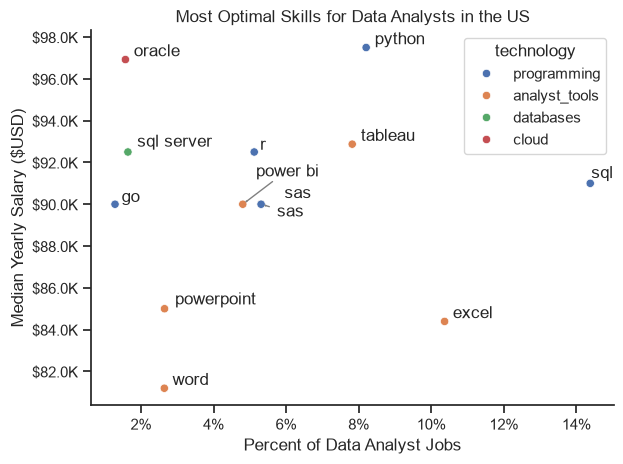

In [91]:
from adjustText import adjust_text
from matplotlib.ticker import PercentFormatter

sns.scatterplot(data = df_DA_skills_tech, x = 'skill_percent', y = 'median_salary', hue = 'technology')
sns.despine()
sns.set_theme(style='ticks')

# Prepare texts for adjustText
texts = []
for i, txt in enumerate(df_DA_skills_tech.index):
    texts.append(plt.text(df_DA_skills_tech['skill_percent'].iloc[i], df_DA_skills_tech['median_salary'].iloc[i], ' ' + txt))

# Adjust text to avoid overlap
adjust_text(texts, arrowprops = dict(arrowstyle= '->', color = 'gray'))

# Set labels
plt.title('Most Optimal Skills for Data Analysts in the US')
plt.xlabel('Percent of Data Analyst Jobs')
plt.ylabel('Median Yearly Salary ($USD)')

# Modify formatter of xaxis and yaxis
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${y/1000}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))

#Adjust layout and display
plt.tight_layout() 
plt.show()

